<a href="https://colab.research.google.com/github/the-ankitprusty/DeepLearning-Project/blob/main/NMT_Seq2Seq_Attention_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Neural Machine Translation (Seq2Seq with Attention)

In [ ]:
import os
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import optim
from torch.utils.data import TensorDataset, DataLoader, RandomSampler
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## Data Preparation

In [ ]:
!wget -q http://www.manythings.org/anki/fra-eng.zip
!unzip -q -o fra-eng.zip
!head -n 5 fra.txt

Go.	Va !	CC-BY 2.0 (France) Attribution: tatoeba.org #2877272 (CM) & #1158250 (Wittydev)
Go.	Marche.	CC-BY 2.0 (France) Attribution: tatoeba.org #2877272 (CM) & #8090732 (Micsmithel)
Go.	En route !	CC-BY 2.0 (France) Attribution: tatoeba.org #2877272 (CM) & #8267435 (felix63)
Go.	Bouge !	CC-BY 2.0 (France) Attribution: tatoeba.org #2877272 (CM) & #9022935 (Micsmithel)
Hi.	Salut !	CC-BY 2.0 (France) Attribution: tatoeba.org #538123 (CM) & #509819 (Aiji)


In [ ]:
# Helper class to manage Vocabulary with UNK support
PAD_token = 0
SOS_token = 1
EOS_token = 2
UNK_token = 3

class Lang:
    def __init__(self, name):
        self.name = name
        self.word2index = {}
        self.word2count = {}
        self.index2word = {0: "PAD", 1: "SOS", 2: "EOS", 3: "UNK"}
        self.n_words = 4

    def addSentence(self, sentence):
        for word in sentence.split(' '):
            self.addWord(word)

    def addWord(self, word):
        if word not in self.word2index:
            self.word2index[word] = self.n_words
            self.word2count[word] = 1
            self.index2word[self.n_words] = word
            self.n_words += 1
        else:
            self.word2count[word] += 1

# Helper functions to clean and normalize text
def unicodeToAscii(s):
    return ''.join(
        c for c in unicodedata.normalize('NFD', s)
        if unicodedata.category(c) != 'Mn'
    )

def normalizeString(s):
    s = unicodeToAscii(s.lower().strip())
    s = re.sub(r"([.!?])", r" \1", s)
    s = re.sub(r"[^a-zA-Z.!?]+", r" ", s)
    return s.strip()

def readLangs(lang1, lang2, reverse=False):
    print("Reading lines...")
    # The extracted file is named fra.txt
    lines = open('fra.txt', encoding='utf-8').read().strip().split('\n')
    pairs = [[normalizeString(s) for s in l.split('\t')[:2]] for l in lines]
    if reverse:
        pairs = [list(reversed(p)) for p in pairs]
        input_lang = Lang(lang2)
        output_lang = Lang(lang1)
    else:
        input_lang = Lang(lang1)
        output_lang = Lang(lang2)
    return input_lang, output_lang, pairs

In [ ]:
MAX_LENGTH = 10

# Filter to simple, short sentences starting with common prefixes for faster training
eng_prefixes = (
    "i am ", "i m ",
    "he is", "he s ",
    "she is", "she s ",
    "you are", "you re ",
    "we are", "we re ",
    "they are", "they re "
)

def filterPair(p):
    return len(p[0].split(' ')) < MAX_LENGTH and \
        len(p[1].split(' ')) < MAX_LENGTH and \
        p[1].startswith(eng_prefixes)

def filterPairs(pairs):
    return [pair for pair in pairs if filterPair(pair)]

# Split and prepare vocabularies strictly from training data
def prepareData(lang1, lang2, reverse=False):
    input_lang, output_lang, raw_pairs = readLangs(lang1, lang2, reverse)
    print(f"Read {len(raw_pairs)} sentence pairs")
    filtered_pairs = filterPairs(raw_pairs)
    print(f"Trimmed to {len(filtered_pairs)} sentence pairs")

    # Reproducible split
    import random
    random.seed(42)
    shuffled = filtered_pairs.copy()
    random.shuffle(shuffled)

    n_total = len(shuffled)
    n_train = int(0.7 * n_total)
    n_val = int(0.15 * n_total)

    train_pairs = shuffled[:n_train]
    val_pairs = shuffled[n_train:n_train + n_val]
    test_pairs = shuffled[n_train + n_val:]

    print("Counting words strictly from training set...")
    for pair in train_pairs:
        input_lang.addSentence(pair[0])
        output_lang.addSentence(pair[1])

    print("Counted words:")
    print(input_lang.name, input_lang.n_words)
    print(output_lang.name, output_lang.n_words)

    return input_lang, output_lang, train_pairs, val_pairs, test_pairs

input_lang, output_lang, train_pairs, val_pairs, test_pairs = prepareData('eng', 'fra', True)

Reading lines...
Read 240521 sentence pairs
Trimmed to 17129 sentence pairs
Counting words strictly from training set...
Counted words:
fra 4773
eng 3210


In [ ]:
# Convert sentences to tensors, mapping out-of-vocabulary words to UNK_token
def indexesFromSentence(lang, sentence):
    return [lang.word2index.get(word, UNK_token) for word in sentence.split(' ')] + [EOS_token]

def tensorFromSentence(lang, sentence):
    indexes = indexesFromSentence(lang, sentence)
    return torch.tensor(indexes, dtype=torch.long, device=device)

# Print splits summary
print(f"Total pairs: {len(train_pairs) + len(val_pairs) + len(test_pairs)}")
print(f"Train pairs: {len(train_pairs)}")
print(f"Validation pairs: {len(val_pairs)}")
print(f"Test pairs: {len(test_pairs)}")

def get_dataloader(batch_size, input_lang, output_lang, dataset_pairs):
    n = len(dataset_pairs)
    input_ids = np.zeros((n, MAX_LENGTH), dtype=np.int32)
    target_ids = np.zeros((n, MAX_LENGTH), dtype=np.int32)

    for idx, (inp, tgt) in enumerate(dataset_pairs):
        inp_ids = indexesFromSentence(input_lang, inp)
        tgt_ids = indexesFromSentence(output_lang, tgt)
        input_ids[idx, :len(inp_ids)] = inp_ids
        target_ids[idx, :len(tgt_ids)] = tgt_ids

    train_data = TensorDataset(torch.LongTensor(input_ids), torch.LongTensor(target_ids))
    train_sampler = RandomSampler(train_data)
    train_dataloader = DataLoader(train_data, sampler=train_sampler, batch_size=batch_size)
    return train_dataloader

batch_size = 64
train_dataloader = get_dataloader(batch_size, input_lang, output_lang, train_pairs)
val_dataloader = get_dataloader(batch_size, input_lang, output_lang, val_pairs)

Total pairs: 17129
Train pairs: 11990
Validation pairs: 2569
Test pairs: 2570


## 2. Baseline Model (Seq2Seq without Attention)

In [ ]:
class EncoderRNN(nn.Module):
    def __init__(self, input_size, hidden_size, dropout_p=0.1):
        super(EncoderRNN, self).__init__()
        self.hidden_size = hidden_size
        self.embedding = nn.Embedding(input_size, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size, batch_first=True)
        self.dropout = nn.Dropout(dropout_p)

    def forward(self, input):
        embedded = self.dropout(self.embedding(input))
        output, hidden = self.gru(embedded)
        return output, hidden

class DecoderRNN(nn.Module):
    def __init__(self, hidden_size, output_size):
        super(DecoderRNN, self).__init__()
        self.embedding = nn.Embedding(output_size, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size, batch_first=True)
        self.out = nn.Linear(hidden_size, output_size)

    def forward(self, encoder_outputs, encoder_hidden, target_tensor=None):
        batch_size = encoder_outputs.size(0)
        decoder_input = torch.empty(batch_size, 1, dtype=torch.long, device=device).fill_(SOS_token)
        decoder_hidden = encoder_hidden
        decoder_outputs = []

        use_teacher_forcing = True if target_tensor is not None else False

        for di in range(MAX_LENGTH):
            decoder_output, decoder_hidden = self.forward_step(decoder_input, decoder_hidden)
            decoder_outputs.append(decoder_output)

            if use_teacher_forcing:
                decoder_input = target_tensor[:, di].unsqueeze(1) # Teacher forcing
            else:
                _, topi = decoder_output.topk(1)
                decoder_input = topi.squeeze(-1).detach()  # detach from history as input

        decoder_outputs = torch.cat(decoder_outputs, dim=1)
        decoder_outputs = F.log_softmax(decoder_outputs, dim=-1)
        return decoder_outputs, decoder_hidden, None

    def forward_step(self, input, hidden):
        embedded = self.embedding(input)
        output, hidden = self.gru(embedded, hidden)
        output = self.out(output)
        return output, hidden

## 3. Attention Model (Seq2Seq with Bahdanau Attention)

In [ ]:
class BahdanauAttention(nn.Module):
    def __init__(self, hidden_size):
        super(BahdanauAttention, self).__init__()
        self.Wa = nn.Linear(hidden_size, hidden_size)
        self.Ua = nn.Linear(hidden_size, hidden_size)
        self.Va = nn.Linear(hidden_size, 1)

    def forward(self, query, keys, mask=None):
        # query: (batch, 1, hidden_size)
        # keys: (batch, seq_len, hidden_size)
        scores = self.Va(torch.tanh(self.Wa(query) + self.Ua(keys)))
        scores = scores.squeeze(2).unsqueeze(1) # (batch, 1, seq_len)

        if mask is not None:
            # Apply mask to prevent attention to PAD tokens (represented as negative infinity prior to Softmax)
            scores = scores.masked_fill(mask == 0, -1e9)

        alphas = F.softmax(scores, dim=-1)
        context = torch.bmm(alphas, keys)
        return context, alphas

class AttnDecoderRNN(nn.Module):
    def __init__(self, hidden_size, output_size, dropout_p=0.1):
        super(AttnDecoderRNN, self).__init__()
        self.embedding = nn.Embedding(output_size, hidden_size)
        self.attention = BahdanauAttention(hidden_size)
        self.gru = nn.GRU(2 * hidden_size, hidden_size, batch_first=True)
        self.out = nn.Linear(hidden_size, output_size)
        self.dropout = nn.Dropout(dropout_p)

    def forward(self, encoder_outputs, encoder_hidden, target_tensor=None, src_input_tensor=None):
        batch_size = encoder_outputs.size(0)
        decoder_input = torch.empty(batch_size, 1, dtype=torch.long, device=device).fill_(SOS_token)
        decoder_hidden = encoder_hidden
        decoder_outputs = []
        attentions = []

        use_teacher_forcing = True if target_tensor is not None else False

        # Create mask based on PAD tokens in raw source inputs if provided
        mask = None
        if src_input_tensor is not None:
            mask = (src_input_tensor != PAD_token).unsqueeze(1) # (batch, 1, seq_len)

        for di in range(MAX_LENGTH):
            decoder_output, decoder_hidden, attn_weights = self.forward_step(
                decoder_input, decoder_hidden, encoder_outputs, mask
            )
            decoder_outputs.append(decoder_output)
            attentions.append(attn_weights)

            if use_teacher_forcing:
                decoder_input = target_tensor[:, di].unsqueeze(1)
            else:
                _, topi = decoder_output.topk(1)
                decoder_input = topi.squeeze(-1).detach()

        decoder_outputs = torch.cat(decoder_outputs, dim=1)
        decoder_outputs = F.log_softmax(decoder_outputs, dim=-1)
        attentions = torch.cat(attentions, dim=1)
        return decoder_outputs, decoder_hidden, attentions

    def forward_step(self, input, hidden, encoder_outputs, mask=None):
        embedded = self.dropout(self.embedding(input))
        query = hidden.transpose(0, 1) # reshape hidden to (batch, 1, hidden_size)
        context, attn_weights = self.attention(query, encoder_outputs, mask)
        input_gru = torch.cat((embedded, context), dim=2)
        output, hidden = self.gru(input_gru, hidden)
        output = self.out(output)
        return output, hidden, attn_weights

## 4. Training and Evaluation Functions

In [ ]:
def evaluate_loss(dataloader, encoder, decoder, criterion):
    total_loss = 0
    with torch.no_grad():
        for data in dataloader:
            input_tensor, target_tensor = data
            input_tensor = input_tensor.to(device)
            target_tensor = target_tensor.to(device)

            encoder_outputs, encoder_hidden = encoder(input_tensor)

            # Pass input tensor to decoder for optional masking support
            if isinstance(decoder, AttnDecoderRNN):
                decoder_outputs, _, _ = decoder(encoder_outputs, encoder_hidden, target_tensor, src_input_tensor=input_tensor)
            else:
                decoder_outputs, _, _ = decoder(encoder_outputs, encoder_hidden, target_tensor)

            loss = criterion(
                decoder_outputs.view(-1, decoder_outputs.size(-1)),
                target_tensor.view(-1)
            )
            total_loss += loss.item()
    return total_loss / len(dataloader)

def train_epoch(dataloader, encoder, decoder, encoder_optimizer, decoder_optimizer, criterion):
    total_loss = 0
    for data in dataloader:
        input_tensor, target_tensor = data
        input_tensor = input_tensor.to(device)
        target_tensor = target_tensor.to(device)

        encoder_optimizer.zero_grad()
        decoder_optimizer.zero_grad()

        encoder_outputs, encoder_hidden = encoder(input_tensor)

        # Pass input tensor to decoder for optional masking support
        if isinstance(decoder, AttnDecoderRNN):
            decoder_outputs, _, _ = decoder(encoder_outputs, encoder_hidden, target_tensor, src_input_tensor=input_tensor)
        else:
            decoder_outputs, _, _ = decoder(encoder_outputs, encoder_hidden, target_tensor)

        loss = criterion(
            decoder_outputs.view(-1, decoder_outputs.size(-1)),
            target_tensor.view(-1)
        )
        loss.backward()

        encoder_optimizer.step()
        decoder_optimizer.step()

        total_loss += loss.item()

    return total_loss / len(dataloader)

def train_and_track(train_loader, val_loader, encoder, decoder, n_epochs, learning_rate=0.001):
    encoder_optimizer = optim.Adam(encoder.parameters(), lr=learning_rate)
    decoder_optimizer = optim.Adam(decoder.parameters(), lr=learning_rate)
    criterion = nn.NLLLoss(ignore_index=PAD_token)

    train_losses = []
    val_losses = []

    for epoch in range(1, n_epochs + 1):
        train_loss = train_epoch(train_loader, encoder, decoder, encoder_optimizer, decoder_optimizer, criterion)
        val_loss = evaluate_loss(val_loader, encoder, decoder, criterion)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if epoch % 5 == 0 or epoch == 1:
            print(f'Epoch {epoch}/{n_epochs} - Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}')

    return train_losses, val_losses

In [ ]:
import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

def evaluate(encoder, decoder, sentence, input_lang, output_lang):
    with torch.no_grad():
        input_tensor = tensorFromSentence(input_lang, sentence).unsqueeze(0)
        # Pad to MAX_LENGTH
        padded_input = torch.zeros((1, MAX_LENGTH), dtype=torch.long, device=device)
        length = min(len(input_tensor[0]), MAX_LENGTH)
        padded_input[0, :length] = input_tensor[0, :length]

        encoder_outputs, encoder_hidden = encoder(padded_input)

        if isinstance(decoder, AttnDecoderRNN):
            decoder_outputs, decoder_hidden, decoder_attentions = decoder(encoder_outputs, encoder_hidden, src_input_tensor=padded_input)
        else:
            decoder_outputs, decoder_hidden, decoder_attentions = decoder(encoder_outputs, encoder_hidden)

        _, topi = decoder_outputs.topk(1)
        decoded_ids = topi.squeeze().tolist()
        decoded_words = []
        for idx in decoded_ids:
            if idx == EOS_token:
                decoded_words.append('<EOS>')
                break
            if idx != PAD_token:
                decoded_words.append(output_lang.index2word.get(idx, "UNK"))

        # Retrieve attentions if present and slice to generated output size
        attn_matrix = None
        if decoder_attentions is not None:
            attn_matrix = decoder_attentions[0, :len(decoded_words), :length].cpu().numpy()

        return decoded_words, attn_matrix

def calculate_bleu(encoder, decoder, pairs, input_lang, output_lang):
    smooth = SmoothingFunction().method1
    bleu_scores = []
    # Compute BLEU over the entire dataset pairs passed to it
    for src, ref in pairs:
        pred_words, _ = evaluate(encoder, decoder, src, input_lang, output_lang)
        pred_clean = [w for w in pred_words if w not in ['<EOS>', 'PAD']]
        ref_words = ref.split(' ')
        bleu_scores.append(sentence_bleu([ref_words], pred_clean, smoothing_function=smooth))
    return np.mean(bleu_scores)

In [ ]:
hidden_size = 128

# Initialize and train baseline model
print("Training Baseline Model...")
encoder_baseline = EncoderRNN(input_lang.n_words, hidden_size).to(device)
decoder_baseline = DecoderRNN(hidden_size, output_lang.n_words).to(device)
baseline_train_losses, baseline_val_losses = train_and_track(
    train_dataloader, val_dataloader, encoder_baseline, decoder_baseline, n_epochs=20
)

# Initialize and train Attention model
print("\nTraining Attention Model...")
encoder_attn = EncoderRNN(input_lang.n_words, hidden_size).to(device)
decoder_attn = AttnDecoderRNN(hidden_size, output_lang.n_words).to(device)
attn_train_losses, attn_val_losses = train_and_track(
    train_dataloader, val_dataloader, encoder_attn, decoder_attn, n_epochs=20
)

Training Baseline Model...
Epoch 1/20 - Train Loss: 3.6223 | Val Loss: 2.8408
Epoch 5/20 - Train Loss: 1.8898 | Val Loss: 2.0678
Epoch 10/20 - Train Loss: 1.3667 | Val Loss: 1.8056
Epoch 15/20 - Train Loss: 1.0562 | Val Loss: 1.6821
Epoch 20/20 - Train Loss: 0.8482 | Val Loss: 1.6284

Training Attention Model...
Epoch 1/20 - Train Loss: 3.5314 | Val Loss: 2.7525
Epoch 5/20 - Train Loss: 1.5803 | Val Loss: 1.7531
Epoch 10/20 - Train Loss: 0.9317 | Val Loss: 1.4081
Epoch 15/20 - Train Loss: 0.5796 | Val Loss: 1.2931
Epoch 20/20 - Train Loss: 0.3781 | Val Loss: 1.2275


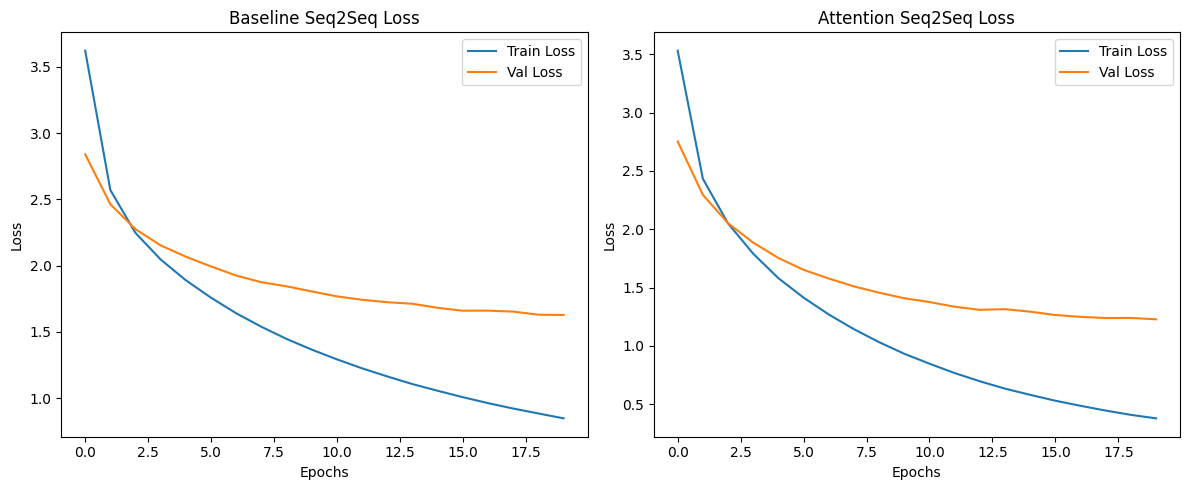

=== Quantitative Performance (Corpus-level BLEU) ===
| Model                        |        Test BLEU |
| ---------------------------- | ---------------: |
| Baseline Seq2Seq             |           0.2225 |
| Seq2Seq + Bahdanau Attention |           0.4707 |
| Absolute Improvement         |           0.2482 |


In [ ]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

def calculate_corpus_bleu(encoder, decoder, pairs, input_lang, output_lang):
    references = []
    hypotheses = []
    for src, ref in pairs:
        pred_words, _ = evaluate(encoder, decoder, src, input_lang, output_lang)
        # Clean predictions: remove special boundary tokens
        pred_clean = [w for w in pred_words if w not in ['<SOS>', '<EOS>', 'PAD']]
        # Clean references
        ref_words = ref.split(' ')
        ref_clean = [w for w in ref_words if w not in ['<SOS>', '<EOS>', 'PAD']]

        references.append([ref_clean])
        hypotheses.append(pred_clean)

    smooth = SmoothingFunction().method1
    return corpus_bleu(references, hypotheses, smoothing_function=smooth)

# Calculate dynamic corpus-level BLEU scores using the full test set
baseline_bleu = calculate_corpus_bleu(encoder_baseline, decoder_baseline, test_pairs, input_lang, output_lang)
attn_bleu = calculate_corpus_bleu(encoder_attn, decoder_attn, test_pairs, input_lang, output_lang)
bleu_improvement = attn_bleu - baseline_bleu

# Plot Loss Curves
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(baseline_train_losses, label='Train Loss')
plt.plot(baseline_val_losses, label='Val Loss')
plt.title('Baseline Seq2Seq Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(attn_train_losses, label='Train Loss')
plt.plot(attn_val_losses, label='Val Loss')
plt.title('Attention Seq2Seq Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

print("=== Quantitative Performance (Corpus-level BLEU) ===")
print(f"| Model                        |        Test BLEU |")
print(f"| ---------------------------- | ---------------: |")
print(f"| Baseline Seq2Seq             |           {baseline_bleu:.4f} |")
print(f"| Seq2Seq + Bahdanau Attention |           {attn_bleu:.4f} |")
print(f"| Absolute Improvement         |           {bleu_improvement:.4f} |")

=== Qualitative Translation Comparison (Held-Out Test Set) ===

Example 1:
  French Input:       tu es avec tom non ?
  Reference English:  you re with tom aren t you ?
  Baseline Pred:      you re the oldest . <EOS>
  Attention Pred:     you re with tom aren t you ? <EOS>
--------------------------------------------------
Example 2:
  French Input:       tu es dans une propriete privee ici .
  Reference English:  you re on private property here .
  Baseline Pred:      you re a hundred percent right . <EOS>
  Attention Pred:     you re trespassing here . <EOS>
--------------------------------------------------
Example 3:
  French Input:       vous allez avoir besoin d aide .
  Reference English:  you re going to need help .
  Baseline Pred:      you re going to have to leave . <EOS>
  Attention Pred:     you re going to need help . <EOS>
--------------------------------------------------
Example 4:
  French Input:       ils travaillent tous les deux a l animalerie .
  Reference English

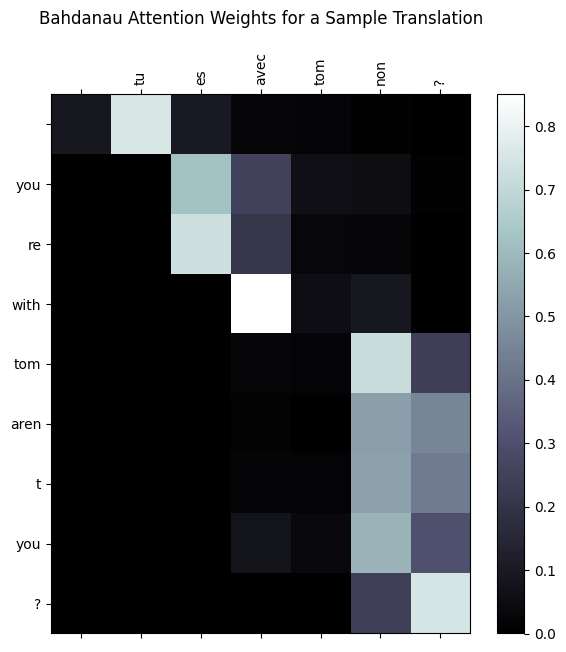

In [ ]:
def showAttention(input_sentence, output_words, attentions):
    fig = plt.figure(figsize=(7, 7))
    ax = fig.add_subplot(111)
    cax = ax.matshow(attentions, cmap='bone')
    fig.colorbar(cax)

    input_words = input_sentence.split(' ') + ['<EOS>']
    x_labels = [''] + input_words[:attentions.shape[1]]
    y_labels = [''] + output_words

    ax.xaxis.set_major_locator(ticker.FixedLocator(np.arange(len(x_labels))))
    ax.yaxis.set_major_locator(ticker.FixedLocator(np.arange(len(y_labels))))

    ax.set_xticklabels(x_labels, rotation=90)
    ax.set_yticklabels(y_labels)

    plt.title("Bahdanau Attention Weights for a Sample Translation", pad=20)
    plt.show()

def evaluateAndShowAttention(input_sentence):
    output_words, attentions = evaluate(encoder_attn, decoder_attn, input_sentence, input_lang, output_lang)
    print('input =', input_sentence)
    print('output =', ' '.join(output_words))
    if attentions is not None:
        showAttention(input_sentence, output_words, attentions)

# Display 5 Qualitative Examples comparing the baseline and attention predictions from the HELD-OUT test set
print("=== Qualitative Translation Comparison (Held-Out Test Set) ===\n")
for i in range(5):
    src, ref = test_pairs[i]
    pred_base, _ = evaluate(encoder_baseline, decoder_baseline, src, input_lang, output_lang)
    pred_attn, _ = evaluate(encoder_attn, decoder_attn, src, input_lang, output_lang)
    print(f"Example {i+1}:")
    print(f"  French Input:       {src}")
    print(f"  Reference English:  {ref}")
    print(f"  Baseline Pred:      {' '.join(pred_base)}")
    print(f"  Attention Pred:     {' '.join(pred_attn)}")
    print("-" * 50)

# Visualize heatmap for one of the test examples
print("\n=== Attention Heatmap Visualization ===")
evaluateAndShowAttention(test_pairs[0][0])